In [ ]:
!pip -q install segmentation-models-pytorch

In [2]:
%pip install -q segmentation-models-pytorch

In [3]:
import torch
import numpy as np
import segmentation_models_pytorch as smp
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import os

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Library installed successfully!")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Library installed successfully!
Device: cuda
GPU: Tesla T4


In [4]:
from google.colab import drive
drive.mount("/content/drive")

import numpy as np

folder = "/content/drive/MyDrive/LULC_Project"

data = np.load(f"{folder}/training_dataset.npz")
split = np.load(f"{folder}/geographic_split.npz")

X = data["X"]
Y = data["Y"]

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]

CLASS_NAMES = [
    "Trees", "Shrubland", "Grassland",
    "Cropland", "Built-up", "Bare land",
    "Snow/Ice", "Water", "Wetland",
    "Mangroves", "Moss/Lichen"
]

print("Input shape:", X.shape)
print("Label shape:", Y.shape)
print("Training patches:", len(train_idx))
print("Validation patches:", len(val_idx))
print("Testing patches:", len(test_idx))

Mounted at /content/drive
Input shape: (60, 2, 256, 256)
Label shape: (60, 256, 256)
Training patches: 43
Validation patches: 8
Testing patches: 9


In [5]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

train_labels = Y[train_idx]

counts = np.bincount(
    train_labels.flatten(),
    minlength=256
)[:11]

present = counts > 0

weights = np.zeros(11, dtype=np.float32)

frequencies = counts[present] / counts[present].sum()

raw_weights = 1.0 / np.sqrt(frequencies)
raw_weights = raw_weights / raw_weights.min()

weights[present] = np.minimum(raw_weights, 10.0)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Device:", device)
print("\nClass weights:\n")

for name, count, weight in zip(CLASS_NAMES, counts, weights):
    print(
        f"{name:15s} | "
        f"Pixels: {count:8d} | "
        f"Weight: {weight:.2f}"
    )

Device: cuda

Class weights:

Trees           | Pixels:  1402659 | Weight: 1.00
Shrubland       | Pixels:        0 | Weight: 0.00
Grassland       | Pixels:   568950 | Weight: 1.57
Cropland        | Pixels:   592680 | Weight: 1.54
Built-up        | Pixels:   244034 | Weight: 2.40
Bare land       | Pixels:     1951 | Weight: 10.00
Snow/Ice        | Pixels:        0 | Weight: 0.00
Water           | Pixels:     7769 | Weight: 10.00
Wetland         | Pixels:        5 | Weight: 10.00
Mangroves       | Pixels:        0 | Weight: 0.00
Moss/Lichen     | Pixels:        0 | Weight: 0.00


In [6]:
from torch.utils.data import TensorDataset, DataLoader

train_data = TensorDataset(
    torch.from_numpy(X[train_idx]).float(),
    torch.from_numpy(Y[train_idx].astype(np.int64))
)

val_data = TensorDataset(
    torch.from_numpy(X[val_idx]).float(),
    torch.from_numpy(Y[val_idx].astype(np.int64))
)

test_data = TensorDataset(
    torch.from_numpy(X[test_idx]).float(),
    torch.from_numpy(Y[test_idx].astype(np.int64))
)

train_loader = DataLoader(
    train_data,
    batch_size=4,
    shuffle=True
)

val_loader = DataLoader(
    val_data,
    batch_size=4,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=4,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 11
Validation batches: 2
Testing batches: 3


In [7]:
import segmentation_models_pytorch as smp
import torch.nn as nn

model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights=None,
    in_channels=2,
    classes=11
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0003
)

print("U-Net model created successfully!")
print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)

U-Net model created successfully!
Total parameters: 14326523


In [8]:
import os
import time
import torch
import numpy as np

EPOCHS = 20

output_dir = "/content/drive/MyDrive/LULC_Project"
os.makedirs(output_dir, exist_ok=True)

history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")
start_time = time.time()

for epoch in range(EPOCHS):

    # Training
    model.train()
    total_train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        predictions = model(images)
        loss = criterion(predictions, labels)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * images.size(0)

    train_loss = total_train_loss / len(train_data)

    # Validation
    model.eval()
    total_val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            predictions = model(images)
            loss = criterion(predictions, labels)

            total_val_loss += loss.item() * images.size(0)

    val_loss = total_val_loss / len(val_data)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    # Save best-performing model
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            os.path.join(output_dir, "unet_sentinel1.pth")
        )

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}",
        flush=True
    )

    # Save progress after every epoch
    np.savez(
        os.path.join(output_dir, "training_history.npz"),
        **history
    )

print("\nTraining completed!")
print("Best validation loss:", round(best_val_loss, 4))
print(
    "Training time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)

Epoch 1/20 | Train Loss: 2.0076 | Val Loss: 2.1848
Epoch 2/20 | Train Loss: 1.6658 | Val Loss: 2.1631
Epoch 3/20 | Train Loss: 1.4026 | Val Loss: 1.9882
Epoch 4/20 | Train Loss: 1.2489 | Val Loss: 1.6085
Epoch 5/20 | Train Loss: 1.0925 | Val Loss: 1.3217
Epoch 6/20 | Train Loss: 0.9639 | Val Loss: 1.0014
Epoch 7/20 | Train Loss: 0.9290 | Val Loss: 1.3466
Epoch 8/20 | Train Loss: 0.8166 | Val Loss: 0.9288
Epoch 9/20 | Train Loss: 0.7938 | Val Loss: 0.7319
Epoch 10/20 | Train Loss: 0.7709 | Val Loss: 1.1569
Epoch 11/20 | Train Loss: 0.7226 | Val Loss: 0.8038
Epoch 12/20 | Train Loss: 0.6494 | Val Loss: 0.7634
Epoch 13/20 | Train Loss: 0.6453 | Val Loss: 1.2860
Epoch 14/20 | Train Loss: 0.6263 | Val Loss: 0.7580
Epoch 15/20 | Train Loss: 0.5392 | Val Loss: 0.5562
Epoch 16/20 | Train Loss: 0.5519 | Val Loss: 0.7745
Epoch 17/20 | Train Loss: 0.5293 | Val Loss: 0.5783
Epoch 18/20 | Train Loss: 0.5469 | Val Loss: 0.7133
Epoch 19/20 | Train Loss: 0.5066 | Val Loss: 0.6905
Epoch 20/20 | Train L

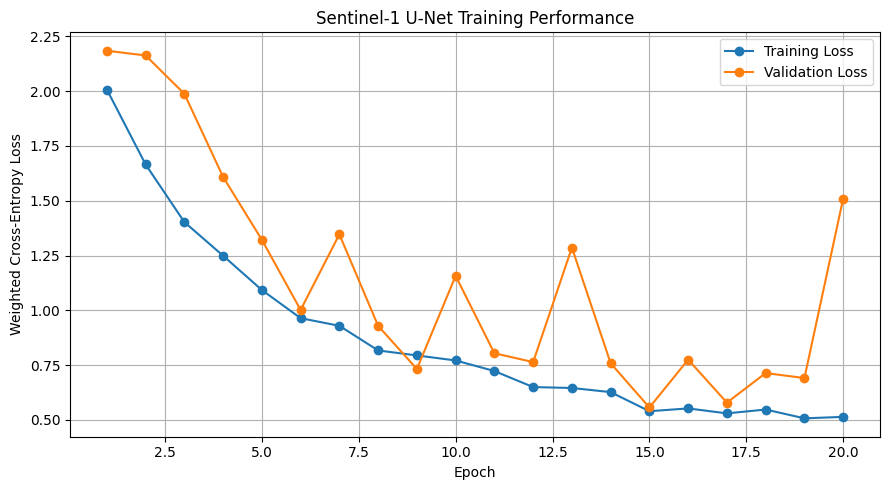

Training graph saved successfully!


In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

epochs = range(1, len(history["train_loss"]) + 1)

plt.plot(
    epochs,
    history["train_loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Weighted Cross-Entropy Loss")
plt.title("Sentinel-1 U-Net Training Performance")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "training_curve.png"),
    dpi=200
)

plt.show()

print("Training graph saved successfully!")

In [11]:
import os

folder = "/content/drive/MyDrive/LULC_Project"

required_files = [
    "training_dataset.npz",
    "geographic_split.npz",
    "unet_sentinel1.pth",
    "training_history.npz",
    "training_curve.png"
]

for filename in required_files:
    path = os.path.join(folder, filename)

    if os.path.exists(path):
        print("OK:", filename)
    else:
        print("MISSING:", filename)

OK: training_dataset.npz
OK: geographic_split.npz
OK: unet_sentinel1.pth
OK: training_history.npz
OK: training_curve.png


In [ ]:
from google.colab import drive
import os

drive.mount("/content/drive")

folder = "/content/drive/MyDrive/LULC_Project"

print("Drive connected:", os.path.exists(folder))

print("Original dataset:",
      os.path.exists(folder + "/training_dataset.npz"))

print("New dataset:",
      os.path.exists(folder + "/urban_training_additions.npz"))

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os

folder = "/content/drive/MyDrive/LULC_Project"

print("Original dataset:",
      os.path.exists(folder + "/training_dataset.npz"))

print("New dataset:",
      os.path.exists(folder + "/urban_training_additions.npz"))

Original dataset: True
New dataset: True


In [3]:
import numpy as np
import os

folder = "/content/drive/MyDrive/LULC_Project"

old = np.load(folder + "/training_dataset.npz")
new = np.load(folder + "/urban_training_additions.npz")
split = np.load(folder + "/geographic_split.npz")

X_old, Y_old = old["X"], old["Y"]
X_new, Y_new = new["X"], new["Y"]

print("===== DATASET SHAPES =====")
print("Original X:", X_old.shape)
print("Original Y:", Y_old.shape)
print("New X:", X_new.shape)
print("New Y:", Y_new.shape)

print("\n===== GEOGRAPHIC SPLIT KEYS =====")
print(split.files)

for key in split.files:
    arr = split[key]
    print(key, "shape:", arr.shape, "sample:", arr[:5])

print("\n===== RADAR MEANS =====")
print("Original VV/VH:", X_old.mean(axis=(0, 2, 3)))
print("New VV/VH:", X_new.mean(axis=(0, 2, 3)))

print("\n===== CLASS DISTRIBUTION =====")

names = [
    "Trees", "Shrubland", "Grassland",
    "Cropland", "Built-up", "Bare land",
    "Snow/Ice", "Water", "Wetland",
    "Mangroves", "Moss/Lichen"
]

for label, Y in [("Original", Y_old), ("New", Y_new)]:
    counts = np.bincount(Y.ravel(), minlength=11)
    percentages = counts / counts.sum() * 100

    print(f"\n{label}:")
    for name, pct in zip(names, percentages):
        if pct > 0:
            print(f"{name}: {pct:.2f}%")

print("\n===== VALIDATION =====")
print("All inputs finite:",
      np.isfinite(X_old).all() and np.isfinite(X_new).all())
print("Valid label indices:",
      np.all(Y_old <= 10) and np.all(Y_new <= 10))
print("Input shapes match:",
      X_old.shape[1:] == X_new.shape[1:])
print("Label shapes match:",
      Y_old.shape[1:] == Y_new.shape[1:])

===== DATASET SHAPES =====
Original X: (60, 2, 256, 256)
Original Y: (60, 256, 256)
New X: (45, 2, 256, 256)
New Y: (45, 256, 256)

===== GEOGRAPHIC SPLIT KEYS =====
['train_idx', 'val_idx', 'test_idx', 'patch_coords', 'groups']
train_idx shape: (43,) sample: [0 1 3 6 8]
val_idx shape: (8,) sample: [12 21 23 36 41]
test_idx shape: (9,) sample: [ 2  4  5  7 20]
patch_coords shape: (60, 2) sample: [[ 8.96450861 47.96931977]
 [ 9.044895   48.80032676]
 [ 8.23853438 47.98650444]
 [ 8.32581855 48.21169   ]
 [ 7.94288955 48.31624935]]
groups shape: (60,) sample: ['212_138' '212_142' '209_138' '209_139' '208_140']

===== RADAR MEANS =====
Original VV/VH: [0.57509416 0.5240161 ]
New VV/VH: [0.6134969  0.55429703]

===== CLASS DISTRIBUTION =====

Original:
Trees: 49.63%
Grassland: 21.24%
Cropland: 19.41%
Built-up: 9.22%
Bare land: 0.09%
Water: 0.42%
Wetland: 0.00%

New:
Trees: 42.05%
Grassland: 12.86%
Cropland: 16.16%
Built-up: 27.01%
Bare land: 0.10%
Water: 1.82%
Wetland: 0.00%

===== VALIDATI

In [4]:
import numpy as np
import os
from pyproj import Transformer

folder = "/content/drive/MyDrive/LULC_Project"

old = np.load(folder + "/training_dataset.npz")
new = np.load(folder + "/urban_training_additions.npz")
split = np.load(folder + "/geographic_split.npz")

X_old, Y_old = old["X"], old["Y"]
X_new, Y_new = new["X"], new["Y"]

train_idx = split["train_idx"]
val_idx = split["val_idx"]
test_idx = split["test_idx"]

# Geographic coordinates of original patches (longitude, latitude)
old_coords = split["patch_coords"]

transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:3035", always_xy=True
)

old_x, old_y = transformer.transform(
    old_coords[:, 0], old_coords[:, 1]
)
old_xy = np.column_stack([old_x, old_y])

# Exact cities and offsets used to collect new patches
cities = {
    "Mannheim": (49.4875, 8.4660),
    "Heidelberg": (49.3988, 8.6724),
    "Karlsruhe": (49.0069, 8.4037),
    "Freiburg": (47.9990, 7.8421),
    "Heilbronn": (49.1427, 9.2109),
    "Ulm": (48.4011, 9.9876),
    "Tuebingen": (48.5216, 9.0576),
    "Pforzheim": (48.8906, 8.7029),
    "Offenburg": (48.4735, 7.9445)
}

offsets = [
    (0, 0), (-5000, 0), (5000, 0),
    (0, -5000), (0, 5000)
]

new_coords = []

for patch_id in new["patch_ids"]:
    city, index = str(patch_id).rsplit("_", 1)

    lat, lon = cities[city]
    x, y = transformer.transform(lon, lat)
    dx, dy = offsets[int(index)]

    new_coords.append([x + dx, y + dy])

new_coords = np.array(new_coords)

# Keep new training patches at least 15 km
# from original validation and test patch centres
heldout_xy = old_xy[
    np.concatenate([val_idx, test_idx])
]

distances = np.linalg.norm(
    new_coords[:, None, :] - heldout_xy[None, :, :],
    axis=2
)

new_train_idx = np.where(
    distances.min(axis=1) >= 15000
)[0]

# Preserve the original geographic split
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

X_train = np.concatenate([
    X_old[train_idx],
    X_new[new_train_idx]
])

Y_train = np.concatenate([
    Y_old[train_idx],
    Y_new[new_train_idx]
])

X_val = X_old[val_idx]
Y_val = Y_old[val_idx]

X_test = X_old[test_idx]
Y_test = Y_old[test_idx]

# Save the reproducible split indices
np.savez(
    folder + "/improved_split_plan.npz",
    old_train_idx=train_idx,
    old_val_idx=val_idx,
    old_test_idx=test_idx,
    new_train_idx=new_train_idx
)

print("===== IMPROVED DATASET =====")
print("Original training patches:", len(train_idx))
print("New usable patches:", len(new_train_idx))
print("Excluded new patches:", len(X_new) - len(new_train_idx))
print("Training X:", X_train.shape)
print("Training Y:", Y_train.shape)
print("Validation patches:", len(X_val))
print("Test patches:", len(X_test))
print("Split plan saved successfully!")

===== IMPROVED DATASET =====
Original training patches: 43
New usable patches: 35
Excluded new patches: 10
Training X: (78, 2, 256, 256)
Training Y: (78, 256, 256)
Validation patches: 8
Test patches: 9
Split plan saved successfully!


In [5]:
%pip install -q segmentation-models-pytorch==0.6.0

In [6]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

from torch.utils.data import Dataset, DataLoader

folder = "/content/drive/MyDrive/LULC_Project"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Training device:", device)
print("Training patches:", len(X_train))
print("Validation patches:", len(X_val))

# Dataset with simple augmentation
class LULCDataset(Dataset):
    def __init__(self, X, Y, augment=False):
        self.X = X
        self.Y = Y
        self.augment = augment

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.tensor(self.X[idx].copy(), dtype=torch.float32)
        y = torch.tensor(self.Y[idx].copy(), dtype=torch.long)

        if self.augment:
            if random.random() < 0.5:
                x = torch.flip(x, [-1])
                y = torch.flip(y, [-1])

            if random.random() < 0.5:
                x = torch.flip(x, [-2])
                y = torch.flip(y, [-2])

        return x, y


train_loader = DataLoader(
    LULCDataset(X_train, Y_train, augment=True),
    batch_size=6,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    LULCDataset(X_val, Y_val),
    batch_size=6,
    shuffle=False,
    num_workers=0
)

# Same architecture as the original model
improved_model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights=None,
    in_channels=2,
    classes=11
).to(device)

# Fine-tune existing trained weights
original_path = os.path.join(folder, "unet_sentinel1_backup.pth")

improved_model.load_state_dict(
    torch.load(
        original_path,
        map_location=device,
        weights_only=True
    )
)

# Recalculate class weights from new training data
counts = np.bincount(Y_train.ravel(), minlength=11)
freq = counts / counts.sum()

weights = np.zeros(11, dtype=np.float32)
present = counts > 0

weights[present] = 1 / np.sqrt(freq[present] + 0.005)
weights[present] /= weights[present].mean()
weights[present] = np.clip(weights[present], 0.3, 3.0)

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(weights, device=device)
)

optimizer = torch.optim.AdamW(
    improved_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

# Validation metrics using confusion matrix
def evaluate(model):
    model.eval()
    confusion = np.zeros((11, 11), dtype=np.int64)
    losses = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            losses.append(criterion(outputs, labels).item())

            preds = outputs.argmax(dim=1)

            actual = labels.cpu().numpy().ravel()
            predicted = preds.cpu().numpy().ravel()

            confusion += np.bincount(
                actual * 11 + predicted,
                minlength=121
            ).reshape(11, 11)

    intersection = np.diag(confusion)
    union = (
        confusion.sum(axis=0)
        + confusion.sum(axis=1)
        - intersection
    )

    iou = np.divide(
        intersection, union,
        out=np.zeros(11, dtype=float),
        where=union > 0
    )

    # Evaluate classes with at least 100 reference pixels
    key_classes = [
        c for c in [0, 2, 3, 4, 7]
        if confusion.sum(axis=1)[c] >= 100
    ]

    miou = float(iou[key_classes].mean())

    return {
        "loss": float(np.mean(losses)),
        "accuracy": float(np.trace(confusion) / confusion.sum()),
        "miou": miou,
        "trees_iou": float(iou[0]),
        "builtup_iou": float(iou[4])
    }


# Baseline validation performance
baseline = evaluate(improved_model)

print("\n===== ORIGINAL MODEL BASELINE =====")
print("Validation accuracy:", round(baseline["accuracy"], 4))
print("Validation mIoU:", round(baseline["miou"], 4))
print("Trees IoU:", round(baseline["trees_iou"], 4))
print("Built-up IoU:", round(baseline["builtup_iou"], 4))

# Fine-tuning
history = []
best_miou = baseline["miou"]
best_path = os.path.join(folder, "unet_sentinel1_improved.pth")
improved_saved = False
patience = 6
epochs_without_improvement = 0

for epoch in range(1, 21):
    improved_model.train()
    train_losses = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = improved_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    metrics = evaluate(improved_model)
    train_loss = float(np.mean(train_losses))

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": metrics["loss"],
        "val_accuracy": metrics["accuracy"],
        "val_miou": metrics["miou"],
        "trees_iou": metrics["trees_iou"],
        "builtup_iou": metrics["builtup_iou"]
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Loss: {train_loss:.4f} | "
        f"Val mIoU: {metrics['miou']:.4f} | "
        f"Trees: {metrics['trees_iou']:.4f} | "
        f"Built-up: {metrics['builtup_iou']:.4f}"
    )

    if metrics["miou"] > best_miou:
        best_miou = metrics["miou"]
        torch.save(improved_model.state_dict(), best_path)
        improved_saved = True
        epochs_without_improvement = 0
        print("  Improved checkpoint saved!")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping: no further validation improvement.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(
    os.path.join(folder, "improved_training_history.csv"),
    index=False
)

print("\n===== TRAINING COMPLETE =====")
print("Original validation mIoU:", round(baseline["miou"], 4))
print("Best new validation mIoU:", round(best_miou, 4))
print("Improved checkpoint saved:", improved_saved)
print("Training history saved!")

Training device: cuda
Training patches: 78
Validation patches: 8

===== ORIGINAL MODEL BASELINE =====
Validation accuracy: 0.8119
Validation mIoU: 0.6675
Trees IoU: 0.8102
Built-up IoU: 0.6109
Epoch 01 | Loss: 0.8486 | Val mIoU: 0.5061 | Trees: 0.5884 | Built-up: 0.5535
Epoch 02 | Loss: 0.7192 | Val mIoU: 0.5728 | Trees: 0.7716 | Built-up: 0.6150
Epoch 03 | Loss: 0.7045 | Val mIoU: 0.6070 | Trees: 0.8016 | Built-up: 0.5500
Epoch 04 | Loss: 0.6881 | Val mIoU: 0.6217 | Trees: 0.8112 | Built-up: 0.5944
Epoch 05 | Loss: 0.6693 | Val mIoU: 0.6345 | Trees: 0.8220 | Built-up: 0.6121
Epoch 06 | Loss: 0.6721 | Val mIoU: 0.6385 | Trees: 0.8266 | Built-up: 0.6188
Early stopping: no further validation improvement.

===== TRAINING COMPLETE =====
Original validation mIoU: 0.6675
Best new validation mIoU: 0.6675
Improved checkpoint saved: False
Training history saved!


In [7]:
import os
import torch
import pandas as pd
import numpy as np

# Preserve the best fine-tuned model so far
candidate_path = os.path.join(
    folder, "unet_sentinel1_finetune_best.pth"
)

torch.save(improved_model.state_dict(), candidate_path)

best_finetune_miou = max(
    item["val_miou"] for item in history
)

best_overall_miou = baseline["miou"]
epochs_without_progress = 0
improved_saved = False

# Continue from epoch 7
for epoch in range(7, 21):

    improved_model.train()
    train_losses = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = improved_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    metrics = evaluate(improved_model)

    history.append({
        "epoch": epoch,
        "train_loss": float(np.mean(train_losses)),
        "val_loss": metrics["loss"],
        "val_accuracy": metrics["accuracy"],
        "val_miou": metrics["miou"],
        "trees_iou": metrics["trees_iou"],
        "builtup_iou": metrics["builtup_iou"]
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Val mIoU: {metrics['miou']:.4f} | "
        f"Trees: {metrics['trees_iou']:.4f} | "
        f"Built-up: {metrics['builtup_iou']:.4f}"
    )

    # Track actual fine-tuning progress
    if metrics["miou"] > best_finetune_miou + 0.0001:
        best_finetune_miou = metrics["miou"]

        torch.save(
            improved_model.state_dict(),
            candidate_path
        )

        epochs_without_progress = 0
        print("  Best fine-tuned checkpoint updated")

    else:
        epochs_without_progress += 1

    # Save improved model only if it beats original baseline
    if metrics["miou"] > best_overall_miou + 0.0001:
        best_overall_miou = metrics["miou"]

        torch.save(
            improved_model.state_dict(),
            os.path.join(
                folder, "unet_sentinel1_improved.pth"
            )
        )

        improved_saved = True
        print("  NEW MODEL BEATS ORIGINAL!")

    if epochs_without_progress >= 5:
        print("Early stopping: validation improvement plateaued")
        break

# Save full history
pd.DataFrame(history).to_csv(
    os.path.join(folder, "improved_training_history.csv"),
    index=False
)

print("\n===== FINAL RESULTS =====")
print("Original validation mIoU:", round(baseline["miou"], 4))
print("Best fine-tuned mIoU:", round(best_finetune_miou, 4))
print("Beat original baseline:", improved_saved)
print("Training history saved!")

Epoch 07 | Val mIoU: 0.6370 | Trees: 0.8082 | Built-up: 0.6239
Epoch 08 | Val mIoU: 0.6629 | Trees: 0.8233 | Built-up: 0.6020
  Best fine-tuned checkpoint updated
Epoch 09 | Val mIoU: 0.6496 | Trees: 0.8232 | Built-up: 0.6119
Epoch 10 | Val mIoU: 0.6379 | Trees: 0.8207 | Built-up: 0.6047
Epoch 11 | Val mIoU: 0.6511 | Trees: 0.8247 | Built-up: 0.6073
Epoch 12 | Val mIoU: 0.6545 | Trees: 0.8178 | Built-up: 0.5525
Epoch 13 | Val mIoU: 0.6582 | Trees: 0.8071 | Built-up: 0.6237
Early stopping: validation improvement plateaued

===== FINAL RESULTS =====
Original validation mIoU: 0.6675
Best fine-tuned mIoU: 0.6629
Beat original baseline: False
Training history saved!


In [8]:
import os
import numpy as np
import torch
import segmentation_models_pytorch as smp

folder = "/content/drive/MyDrive/LULC_Project"

models = {
    "Original": folder + "/unet_sentinel1_backup.pth",
    "Fine-tuned": folder + "/unet_sentinel1_finetune_best.pth"
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def test_model(path):
    net = smp.Unet(
        encoder_name="resnet18",
        encoder_weights=None,
        in_channels=2,
        classes=11
    ).to(device)

    net.load_state_dict(
        torch.load(path, map_location=device, weights_only=True)
    )
    net.eval()

    confusion = np.zeros((11, 11), dtype=np.int64)

    with torch.no_grad():
        for i in range(0, len(X_test), 2):
            x = torch.from_numpy(
                X_test[i:i+2].copy()
            ).float().to(device)

            pred = net(x).argmax(1).cpu().numpy().ravel()
            actual = Y_test[i:i+2].ravel()

            confusion += np.bincount(
                actual * 11 + pred,
                minlength=121
            ).reshape(11, 11)

    intersection = np.diag(confusion)
    union = (
        confusion.sum(0)
        + confusion.sum(1)
        - intersection
    )

    iou = np.divide(
        intersection, union,
        out=np.zeros(11, dtype=float),
        where=union > 0
    )

    present = confusion.sum(1) >= 100

    return {
        "Accuracy": np.trace(confusion) / confusion.sum(),
        "mIoU": iou[present].mean(),
        "Trees IoU": iou[0],
        "Built-up IoU": iou[4]
    }

for name, path in models.items():
    print("\n====", name, "====")

    result = test_model(path)

    for metric, value in result.items():
        print(f"{metric}: {value:.4f}")


==== Original ====
Accuracy: 0.7760
mIoU: 0.4982
Trees IoU: 0.7569
Built-up IoU: 0.5255

==== Fine-tuned ====
Accuracy: 0.7863
mIoU: 0.5068
Trees IoU: 0.7882
Built-up IoU: 0.5193


In [10]:
import ee

ee.Authenticate(auth_mode="notebook")

ee.Initialize(project="mydataportfolio-484121")

print("Google Earth Engine connected successfully!")

To authorize access needed by Earth Engine, open the following URL in a web browser and follow the instructions. If the web browser does not start automatically, please manually browse the URL below.

    https://code.earthengine.google.com/client-auth?scopes=https%3A//www.googleapis.com/auth/earthengine%20https%3A//www.googleapis.com/auth/cloud-platform%20https%3A//www.googleapis.com/auth/drive%20https%3A//www.googleapis.com/auth/devstorage.full_control&request_id=_5MDJZr4wCcjLwwG1pVFXctcys3mnC4yah2LKARgSII&tc=xa9vpDOBt7LaI6jD_4s_q20aTnkU_0esyLsG38KWwQI&cc=YVAFgIlrQniZp1-DFREB9bNwmZtz9t8woRcYPyCCIz4

The authorization workflow will generate a code, which you should paste in the box below.
Enter verification code: 4/1AUn6Hd__5oxpgGiMhaA3HY-3IjComY_C7J-1rr5DdHSBEN65GGdHFLac_z0

Successfully saved authorization token.
Google Earth Engine connected successfully!


In [11]:
import ee
import requests
import numpy as np
import torch
from pyproj import Transformer
from rasterio.io import MemoryFile

ee.Initialize(project="mydataportfolio-484121")

# Stuttgart
lat, lon = 48.7758, 9.1829

transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:3035", always_xy=True
)

cx, cy = transformer.transform(lon, lat)
xmin, ymax = cx - 1280, cy + 1280

region = ee.Geometry.Rectangle(
    [cx-1280, cy-1280, cx+1280, cy+1280],
    proj="EPSG:3035",
    geodesic=False
)

s1 = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(region)
    .filterDate("2021-01-01", "2022-01-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"))
    .select(["VV", "VH"])
)

worldcover = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
    .rename("label")
    .toFloat()
)

combined = s1.median().toFloat().addBands(worldcover)

url = combined.getDownloadURL({
    "bands": ["VV", "VH", "label"],
    "crs": "EPSG:3035",
    "crs_transform": [10, 0, xmin, 0, -10, ymax],
    "dimensions": [256, 256],
    "format": "GEO_TIFF"
})

response = requests.get(url, timeout=120)
response.raise_for_status()

with MemoryFile(response.content) as mem:
    with mem.open() as src:
        patch = src.read(masked=True)

assert patch.shape == (3, 256, 256)
assert not np.ma.getmaskarray(patch).any()

patch = patch.data.astype(np.float32)

vv = (np.clip(patch[0], -30, 5) + 30) / 35
vh = (np.clip(patch[1], -35, 0) + 35) / 35

radar = np.stack([vv, vh]).astype(np.float32)

codes = [10,20,30,40,50,60,70,80,90,95,100]
reference = np.full((256,256), -1, dtype=np.int16)

for i, code in enumerate(codes):
    reference[np.rint(patch[2]) == code] = i

valid = reference >= 0

# Reuse the model-evaluation function from Step 48
for name, path in models.items():

    net = smp.Unet(
        encoder_name="resnet18",
        encoder_weights=None,
        in_channels=2,
        classes=11
    ).to(device)

    net.load_state_dict(
        torch.load(path, map_location=device, weights_only=True)
    )
    net.eval()

    with torch.no_grad():
        inp = torch.from_numpy(radar[None]).to(device)
        pred = net(inp).argmax(1)[0].cpu().numpy()

    accuracy = np.mean(pred[valid] == reference[valid]) * 100

    print(f"\n===== {name.upper()} MODEL =====")
    print(f"Pixel accuracy: {accuracy:.2f}%")
    print(f"Trees coverage: {np.mean(pred == 0)*100:.2f}%")
    print(f"Built-up coverage: {np.mean(pred == 4)*100:.2f}%")

    for class_id, class_name in [(0, "Trees"), (4, "Built-up")]:
        intersection = np.sum(
            (pred == class_id) &
            (reference == class_id) & valid
        )
        union = np.sum(
            ((pred == class_id) | (reference == class_id)) & valid
        )
        print(
            f"{class_name} IoU: "
            f"{intersection/union:.4f}"
        )


===== ORIGINAL MODEL =====
Pixel accuracy: 67.14%
Trees coverage: 2.66%
Built-up coverage: 96.72%
Trees IoU: 0.0670
Built-up IoU: 0.6668

===== FINE-TUNED MODEL =====
Pixel accuracy: 71.73%
Trees coverage: 9.48%
Built-up coverage: 89.84%
Trees IoU: 0.2242
Built-up IoU: 0.6975


,Month,Trees (%),Grassland (%),Cropland (%),Built-up (%),Water (%)
0,2025-01,1.08,0.00,0.0,98.52,0.40
1,2025-02,1.04,0.00,0.0,98.55,0.41
2,2025-03,0.37,0.00,0.0,98.94,0.69
3,2025-04,1.09,0.00,0.0,98.30,0.61
4,2025-05,2.23,0.12,0.0,96.66,0.99
5,2025-06,2.97,0.04,0.0,96.46,0.54
6,2025-07,2.14,0.06,0.0,97.24,0.56
7,2025-08,2.77,0.19,0.0,96.51,0.52
8,2025-09,2.15,0.16,0.0,97.26,0.43
9,2025-10,1.77,0.00,0.0,97.53,0.70


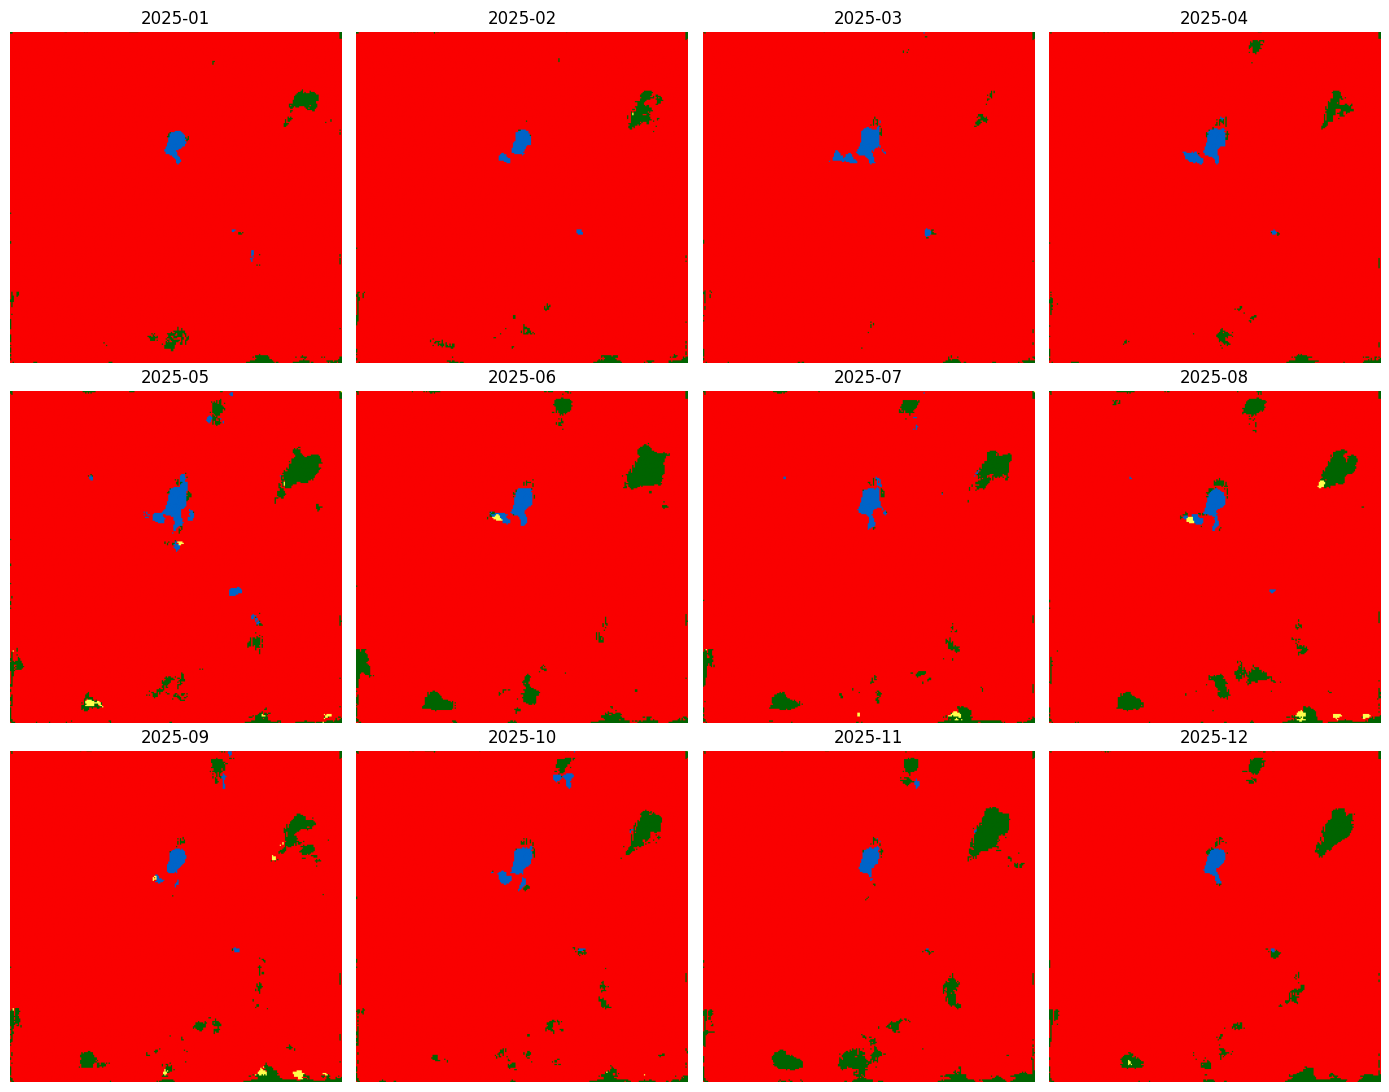

Improved predictions saved successfully!


In [12]:
import os
import numpy as np
import pandas as pd
import torch
import rasterio
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from matplotlib.colors import ListedColormap

folder = "/content/drive/MyDrive/LULC_Project"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load best fine-tuned model
model_2025 = smp.Unet(
    encoder_name="resnet18",
    encoder_weights=None,
    in_channels=2,
    classes=11
).to(device)

model_2025.load_state_dict(
    torch.load(
        folder + "/unet_sentinel1_finetune_best.pth",
        map_location=device,
        weights_only=True
    )
)
model_2025.eval()

months = pd.period_range("2025-01", "2025-12", freq="M")
predictions = []
results = []

for month in months:
    month_name = str(month)

    path = (
        folder + "/monthly_patches/"
        + f"sentinel1_{month_name}.tif"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    with rasterio.open(path) as src:
        radar = src.read().astype(np.float32)

    assert radar.shape == (2, 256, 256)
    assert np.isfinite(radar).all()

    vv = (np.clip(radar[0], -30, 5) + 30) / 35
    vh = (np.clip(radar[1], -35, 0) + 35) / 35

    x = np.stack([vv, vh])[None]

    with torch.no_grad():
        tensor = torch.from_numpy(x).to(device)
        pred = model_2025(tensor).argmax(1)[0]
        pred = pred.cpu().numpy()

    predictions.append(pred)

    results.append({
        "Month": month_name,
        "Trees (%)": round(np.mean(pred == 0) * 100, 2),
        "Grassland (%)": round(np.mean(pred == 2) * 100, 2),
        "Cropland (%)": round(np.mean(pred == 3) * 100, 2),
        "Built-up (%)": round(np.mean(pred == 4) * 100, 2),
        "Water (%)": round(np.mean(pred == 7) * 100, 2)
    })

df_2025 = pd.DataFrame(results)

display(df_2025)

np.savez_compressed(
    folder + "/monthly_predictions_finetuned.npz",
    predicted_maps=np.array(predictions),
    month_names=np.array([str(m) for m in months])
)

# Display all 12 maps
colors = [
    "#006400", "#ffbb22", "#ffff4c", "#f096ff",
    "#fa0000", "#b4b4b4", "#f0f0f0", "#0064c8",
    "#0096a0", "#00cf75", "#fae6a0"
]

cmap = ListedColormap(colors)

fig, axes = plt.subplots(3, 4, figsize=(14, 11))

for i, ax in enumerate(axes.flat):
    ax.imshow(predictions[i], cmap=cmap, vmin=0, vmax=10)
    ax.set_title(str(months[i]))
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Improved predictions saved successfully!")

In [13]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp

from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
folder = "/content/drive/MyDrive/LULC_Project"

# Augment radar brightness during training
class RadarAugmentedDataset(Dataset):
    def __init__(self, X, Y):
        self.X = X
        self.Y = Y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        x = torch.tensor(self.X[index].copy(), dtype=torch.float32)
        y = torch.tensor(self.Y[index].copy(), dtype=torch.long)

        # Horizontal and vertical flips
        if random.random() < 0.5:
            x = torch.flip(x, [-1])
            y = torch.flip(y, [-1])

        if random.random() < 0.5:
            x = torch.flip(x, [-2])
            y = torch.flip(y, [-2])

        # Simulate radar intensity variations
        if random.random() < 0.85:
            shift = torch.empty(2, 1, 1).uniform_(-0.16, 0.16)
            x = torch.clamp(x + shift, 0, 1)

        # Mild radar noise
        if random.random() < 0.5:
            noise = torch.randn_like(x) * 0.015
            x = torch.clamp(x + noise, 0, 1)

        return x, y


train_loader = DataLoader(
    RadarAugmentedDataset(X_train, Y_train),
    batch_size=6,
    shuffle=True,
    num_workers=0
)

# Load the best fine-tuned checkpoint
improved_model = smp.Unet(
    encoder_name="resnet18",
    encoder_weights=None,
    in_channels=2,
    classes=11
).to(device)

improved_model.load_state_dict(
    torch.load(
        folder + "/unet_sentinel1_finetune_best.pth",
        map_location=device,
        weights_only=True
    )
)

# Use the existing class weights
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(weights, dtype=torch.float32, device=device)
)

optimizer = torch.optim.AdamW(
    improved_model.parameters(),
    lr=0.00005,
    weight_decay=0.0001
)

# 'evaluate' and 'val_loader' come from Step 46
baseline_metrics = evaluate(improved_model)
best_miou = baseline_metrics["miou"]

save_path = folder + "/unet_sentinel1_robust.pth"

# Save starting checkpoint so file always exists
torch.save(improved_model.state_dict(), save_path)

history_robust = []
no_improvement = 0

print("Starting validation mIoU:", round(best_miou, 4))

for epoch in range(1, 13):
    improved_model.train()
    losses = []

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = improved_model(images)

        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

    metrics = evaluate(improved_model)

    history_robust.append({
        "epoch": epoch,
        "train_loss": float(np.mean(losses)),
        **metrics
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Val mIoU: {metrics['miou']:.4f} | "
        f"Trees IoU: {metrics['trees_iou']:.4f} | "
        f"Built-up IoU: {metrics['builtup_iou']:.4f}"
    )

    if metrics["miou"] > best_miou + 0.0001:
        best_miou = metrics["miou"]
        torch.save(improved_model.state_dict(), save_path)
        no_improvement = 0
        print("  Best robust checkpoint saved!")
    else:
        no_improvement += 1

    if no_improvement >= 4:
        print("Early stopping.")
        break

pd.DataFrame(history_robust).to_csv(
    folder + "/robust_training_history.csv",
    index=False
)

print("\n===== ROBUST TRAINING COMPLETE =====")
print("Starting mIoU:", round(baseline_metrics["miou"], 4))
print("Best robust mIoU:", round(best_miou, 4))
print("Model saved:", save_path)

Starting validation mIoU: 0.6629
Epoch 01 | Val mIoU: 0.5408 | Trees IoU: 0.5136 | Built-up IoU: 0.5361
Epoch 02 | Val mIoU: 0.6155 | Trees IoU: 0.7617 | Built-up IoU: 0.5710
Epoch 03 | Val mIoU: 0.6295 | Trees IoU: 0.7934 | Built-up IoU: 0.5205
Epoch 04 | Val mIoU: 0.5996 | Trees IoU: 0.7807 | Built-up IoU: 0.5997
Early stopping.

===== ROBUST TRAINING COMPLETE =====
Starting mIoU: 0.6629
Best robust mIoU: 0.6629
Model saved: /content/drive/MyDrive/LULC_Project/unet_sentinel1_robust.pth


In [14]:
from pathlib import Path
import shutil
import py_compile

folder = Path("/content/drive/MyDrive/LULC_Project")

app_path = folder / "app.py"
backup_path = folder / "app_original.py"
model_path = folder / "unet_sentinel1_finetune_best.pth"

assert app_path.exists(), "app.py missing"
assert model_path.exists(), "Fine-tuned model missing"

# Preserve the original application
if not backup_path.exists():
    shutil.copy2(app_path, backup_path)

code = app_path.read_text(encoding="utf-8")

old_name = '"unet_sentinel1.pth"'
new_name = '"unet_sentinel1_finetune_best.pth"'

if old_name in code:
    code = code.replace(old_name, new_name, 1)
    app_path.write_text(code, encoding="utf-8")

elif new_name not in code:
    raise ValueError("Could not find model filename in app.py")

py_compile.compile(str(app_path), doraise=True)

print("Streamlit updated successfully!")
print("Using model:", model_path.name)
print("Original app backup:", backup_path.name)

Streamlit updated successfully!
Using model: unet_sentinel1_finetune_best.pth
Original app backup: app_original.py


In [15]:
%pip install -q streamlit

In [16]:
import subprocess
import time
import requests

app_path = "/content/drive/MyDrive/LULC_Project/app.py"

log = open("/tmp/lulc_streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", app_path,
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false"
    ],
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Server running:", process.poll() is None)

try:
    r = requests.get("http://localhost:8501/_stcore/health", timeout=5)
    print("Server health:", r.status_code, r.text)
except Exception as e:
    print("Connection error:", e)

Server running: True
Server health: 200 ok


In [17]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>